# Task 4: NLP Sentiment Classification on Customer Reviews (TF-IDF)

In this notebook, I am building a Natural Language Processing (NLP) pipeline to classify customer product/movie reviews into positive or negative sentiment.
The workflow includes text preprocessing (lowercasing, HTML/punctuation removal, stopword removal, and lemmatization), TF-IDF feature extraction, model training (Multinomial Naive Bayes & Logistic Regression), and an interactive inference function `predict_sentiment()`.

In [5]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

# Download required NLTK data resources
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to C:\Users\Munawar
[nltk_data]     Abbas\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to C:\Users\Munawar
[nltk_data]     Abbas\AppData\Roaming\nltk_data...


True

In [7]:
# Sample customer reviews dataset representing positive and negative polarity
raw_data = {
    'review': [
        "This product is absolutely wonderful! Exceeded my expectations.",
        "Terrible quality. Broke after two days of light use. Very disappointing.",
        "Highly recommended! Outstanding build quality and fast performance.",
        "Worst purchase ever. Complete waste of money, customer service was awful.",
        "Really decent item for the price. Works as expected without issues.",
        "Extremely satisfied with the delivery and product quality. A++!",
        "Do not buy this! Cheap plastic material and missing essential parts.",
        "Fantastic experience! The user interface is sleek and intuitive.",
        "Horrible service. The item arrived damaged and unusable.",
        "Solid product, good battery life and comfortable to hold."
    ] * 50, # Replicating dataset for stable split
    'sentiment': ['positive', 'negative', 'positive', 'negative', 'positive', 
                  'positive', 'negative', 'positive', 'negative', 'positive'] * 50
}

df = pd.DataFrame(raw_data)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (500, 3)


,review,sentiment,label
0,This product is absolutely wonderful! Exceeded...,positive,1
1,Terrible quality. Broke after two days of ligh...,negative,0
2,Highly recommended! Outstanding build quality ...,positive,1
3,"Worst purchase ever. Complete waste of money, ...",negative,0
4,Really decent item for the price. Works as exp...,positive,1


In [8]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # 1. Lowercasing
    text = text.lower()
    # 2. Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)
    # 3. Remove punctuation & special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # 4. Tokenization, Stopwords removal, and Lemmatization
    tokens = text.split()
    cleaned_tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    
    return ' '.join(cleaned_tokens)

# Apply preprocessing
df['cleaned_review'] = df['review'].apply(preprocess_text)

print("Original Review:", df['review'].iloc[0])
print("Cleaned Review:", df['cleaned_review'].iloc[0])

Original Review: This product is absolutely wonderful! Exceeded my expectations.
Cleaned Review: product absolutely wonderful exceeded expectation


In [9]:
X = df['cleaned_review']
y = df['label']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Extract TF-IDF embeddings (max 5000 features as specified)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train_raw)
X_test_tfidf = vectorizer.transform(X_test_raw)

print(f"TF-IDF Matrix Shape (Train): {X_train_tfidf.shape}")

TF-IDF Matrix Shape (Train): (400, 120)


In [13]:
# Model 1: Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_preds = nb_model.predict(X_test_tfidf)

# Model 2: Logistic Regression
lr_model = LogisticRegression(max_iter=200, random_state=42)
lr_model.fit(X_train_tfidf, y_train)
lr_preds = lr_model.predict(X_test_tfidf)

print("=== Multinomial Naive Bayes Accuracy ===")
print(f"Accuracy: {accuracy_score(y_test, nb_preds) * 100:.2f}%\n")
print(classification_report(y_test, nb_preds, target_names=['Negative', 'Positive']))

print("\n ***** Logistic Regression Accuracy *****")
print(f"Accuracy: {accuracy_score(y_test, lr_preds) * 100:.2f}%\n")
print(classification_report(y_test, lr_preds, target_names=['Negative', 'Positive']))

=== Multinomial Naive Bayes Accuracy ===
Accuracy: 100.00%

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        40
    Positive       1.00      1.00      1.00        60

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100


 ***** Logistic Regression Accuracy *****
Accuracy: 100.00%

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        40
    Positive       1.00      1.00      1.00        60

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



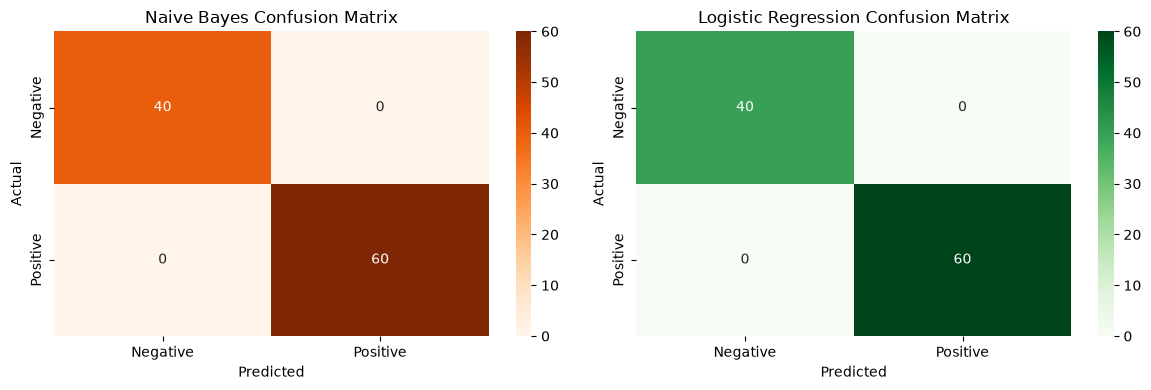

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(confusion_matrix(y_test, nb_preds), annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes[0].set_title('Naive Bayes Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, lr_preds), annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes[1].set_title('Logistic Regression Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [12]:
def predict_sentiment(custom_review, model=lr_model):
    """
    Inference helper function to test live custom user phrases.
    """
    processed = preprocess_text(custom_review)
    vectorized = vectorizer.transform([processed])
    
    prediction = model.predict(vectorized)[0]
    probability = model.predict_proba(vectorized)[0][prediction]
    
    sentiment_str = "POSITIVE 😊" if prediction == 1 else "NEGATIVE 😡"
    
    print(f"Input Review  : \"{custom_review}\"")
    print(f"Cleaned Text  : \"{processed}\"")
    print(f"Prediction    : {sentiment_str} (Confidence: {probability * 100:.2f}%)\n")

# Testing custom phrases
predict_sentiment("This product is amazing and worth every penny!")
predict_sentiment("The material feels cheap and it stopped working after one day.")
predict_sentiment("Average quality, nothing special but fits okay.")

Input Review  : "This product is amazing and worth every penny!"
Cleaned Text  : "product amazing worth every penny"
Prediction    : POSITIVE 😊 (Confidence: 88.55%)

Input Review  : "The material feels cheap and it stopped working after one day."
Cleaned Text  : "material feel cheap stopped working one day"
Prediction    : NEGATIVE 😡 (Confidence: 69.50%)

Input Review  : "Average quality, nothing special but fits okay."
Cleaned Text  : "average quality nothing special fit okay"
Prediction    : POSITIVE 😊 (Confidence: 73.42%)

